# Do que o cliente reclama? — apresentação dos resultados

**Vitor Neves de Lima** · Processamento de Linguagem Natural · Ibmec BH · 2026/2

Este notebook reúne, na ordem em que o trabalho foi feito, os dados, os modelos, as tabelas e os gráficos do artigo. Ele **não treina nada pesado**: as linhas de base são treinadas aqui em segundos, e os resultados que precisaram de GPU (BERTimbau e Qwen, rodados no Google Colab) são lidos da pasta `results/` do repositório. Roda em CPU em poucos minutos.

| Seção | Conteúdo |
|---|---|
| 1 | O problema |
| 2 | Dados: RePro (gabarito humano) e Olist (atraso real) |
| 3 | Linhas de base: regras e TF-IDF |
| 4 | **H1** — o BERTimbau supera as linhas de base? |
| 5 | **H2** — rótulos de um LLM substituem rótulos humanos? |
| 6 | **H3** — "entrega negativa" acompanha o atraso real? |
| 7 | Conclusões, limitações e onde está cada coisa |

Repositório: https://github.com/vnevesl/pln-absa-olist

In [1]:
# Preparação: no Colab, clona o repositório; localmente, usa a pasta do projeto
import os, sys
from pathlib import Path
if "google.colab" in sys.modules:
    !git clone -q https://github.com/vnevesl/pln-absa-olist.git 2>/dev/null || git -C pln-absa-olist pull -q
    %cd /content/pln-absa-olist
    !pip -q install -e .
    COLAB = True
elif Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path("src").resolve()))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from absa.config import ASPECTS, LABEL_COLUMNS, POLARITIES, SEED
from absa.metrics import bootstrap_ci, detection_f1, holm, macro_f1, paired_bootstrap, per_aspect_report, tuple_f1
from absa.repro import load_repro, label_distribution

pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COR = {"humano": "#1f4e79", "tfidf": "#9dc3e6", "llm": "#c55a11", "llm3": "#f4b183", "controle": "#a6a6a6"}
RES = Path("results")
print("pronto")

pronto


## 1. O problema

A nota em estrelas diz **quanto** o cliente gostou, mas não **do quê**. Um comentário como *"o produto é ótimo, mas chegou dez dias atrasado"* elogia o produto e critica a entrega ao mesmo tempo: reduzido a uma nota, perde justamente a informação útil (o problema é da transportadora, não do produto).

A tarefa é **análise de sentimentos baseada em aspectos (ACSA)**. Para cada comentário e cada um de **5 aspectos** — produto, entrega, recebimento, anúncio e outros — o modelo escolhe **1 de 4 classes**: ausente, positivo, negativo ou neutro.

**Métrica principal:** F1 de pares (aspecto, polaridade). Um acerto é acertar *qual* aspecto foi comentado *e* com qual opinião.

## 2. Dados

### 2.1 RePro — o gabarito humano
Avaliações da Americanas/B2W anotadas por pessoas (PROPOR 2024). O corpus marca os tópicos de cada avaliação, mas a polaridade é **da avaliação inteira**, não de cada tópico. Por isso: polaridade única → vale para todos os tópicos marcados; polaridade mista → a avaliação é descartada (não dá para saber qual opinião é de qual tópico).

In [2]:
treino, val, teste, descartados = load_repro()
demo, val_dev = train_test_split(val, train_size=200, stratify=val.nota, random_state=SEED)
demo, val_dev = demo.reset_index(drop=True), val_dev.reset_index(drop=True)
total = len(treino) + len(val) + len(teste) + len(descartados)
display(pd.DataFrame({"avaliações": [total, len(descartados), len(treino), len(val), len(teste)]},
                     index=["anotadas no RePro", "descartadas (polaridade mista)", "treino", "validação", "teste"]))
print(f"Descartadas: {len(descartados) / total:.1%} do total")
print("Validação dividida em: demo (200, só para exemplos do prompt do LLM) e val_dev (599, escolha de época e concordância)")

,avaliações
anotadas no RePro,10003
descartadas (polaridade mista),2018
treino,5589
validação,799
teste,1597


Descartadas: 20.2% do total
Validação dividida em: demo (200, só para exemplos do prompt do LLM) e val_dev (599, escolha de época e concordância)


**Rótulos por aspecto no teste** — desbalanceado: "produto" domina e "neutro" é raro

,ausente,positivo,negativo,neutro
produto,395,807,369,26
entrega,1111,295,170,21
recebimento,1345,64,188,0
anuncio,1468,25,96,8
outros,1192,81,273,51


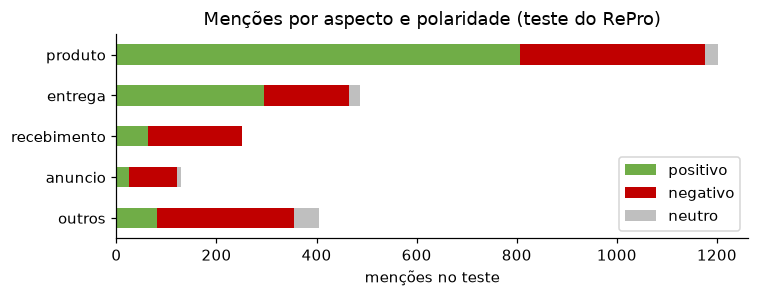

In [3]:
dist = label_distribution(teste)[POLARITIES]
display(Markdown("**Rótulos por aspecto no teste** — desbalanceado: \"produto\" domina e \"neutro\" é raro"))
display(dist)
ax = dist.drop(columns="ausente").plot.barh(stacked=True, figsize=(7, 2.8), color=["#70ad47", "#c00000", "#bfbfbf"])
ax.set_xlabel("menções no teste"); ax.set_title("Menções por aspecto e polaridade (teste do RePro)"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

In [4]:
display(Markdown("**Exemplos do gabarito**"))
ex = teste.sample(4, random_state=3)
display(ex[["texto_modelo", *LABEL_COLUMNS]].rename(columns=lambda c: c.removeprefix("asp_")))

**Exemplos do gabarito**

,texto_modelo,produto,entrega,recebimento,anuncio,outros
147,"Bom produto. Ótimo produto, bom custo benefício, leve e boa para quem deseja uma tv básica para o dia a dia, entrega...",positivo,positivo,ausente,ausente,ausente
937,"Péssimo produto. não comprem este teclado de péssima qualidade, em menos de uma semana parou de funcionar. Estou ten...",negativo,ausente,ausente,ausente,negativo
877,Problema na entrega. Não recebi o produto e cancelei o pedido. Americanas.com está tercerizando as vendas para Megam...,ausente,negativo,ausente,ausente,negativo
1000,Ele chegou? Se tivesse chegado até poderia avaliar,ausente,neutro,ausente,ausente,ausente


### 2.2 Olist — o atraso real
~99 mil avaliações de pedidos reais, **sem rótulos de aspecto**, mas com a data em que o pedido chegou e a data prometida. Atrasado = entregue depois da data prometida. É uma "verdade de campo" que não depende de anotação humana nem de IA, e serve para a H3.

comentários escritos: 40,641 · de pedidos entregues: 38,796 · atrasados: 3,747


nota (% da linha),1,2,3,4,5
atrasado,63.9,9.1,9.3,6.5,11.2
no prazo,13.7,4.7,8.8,16.1,56.8


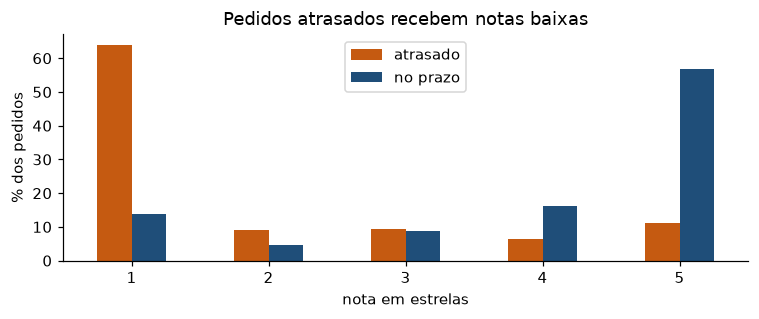

A nota já indica que algo deu errado; só o texto diz o quê.


In [5]:
from absa.data import load_reviews
from absa.sampling import gold_exclusion, olist_split
olist = load_reviews()
entregues = olist[olist.entregue]
print(f"comentários escritos: {len(olist):,} · de pedidos entregues: {len(entregues):,} · atrasados: {int(entregues.atrasado.sum()):,}")
tab = pd.crosstab(entregues.atrasado.map({True: "atrasado", False: "no prazo"}), entregues.nota, normalize="index") * 100
display(tab.round(1).rename_axis(index=None, columns="nota (% da linha)"))
ax = tab.T.plot.bar(figsize=(7, 3), color=[COR["humano"], COR["llm"]][::-1], rot=0)
ax.set_ylabel("% dos pedidos"); ax.set_xlabel("nota em estrelas"); ax.set_title("Pedidos atrasados recebem notas baixas"); ax.legend(title=None)
plt.tight_layout(); plt.show()
print("A nota já indica que algo deu errado; só o texto diz o quê.")

## 3. Linhas de base: regras e TF-IDF

- **Regras:** listas de palavras por aspecto e polaridade — o piso mínimo.
- **TF-IDF + classificador:** o texto vira um vetor de pesos de palavras e pares de palavras; um classificador de 4 classes por aspecto (regressão logística ou *random forest*).

Treinadas aqui mesmo, em segundos.

In [6]:
from absa.heuristics import heuristic_labels
from absa.models.baseline import TfidfAspectClassifier
from absa.preprocess import clean_classic

def avaliar(pred):
    f, lo, hi = bootstrap_ci(teste, pred)
    return {"F1 de pares": f, "IC 95%": f"{lo:.3f}–{hi:.3f}", "F1 macro": macro_f1(teste, pred), "F1 detecção": detection_f1(teste, pred)}

regras = pd.DataFrame([heuristic_labels(t) for t in teste.texto_modelo]); regras.columns = LABEL_COLUMNS
X_treino, X_teste = treino.texto_modelo.map(clean_classic), teste.texto_modelo.map(clean_classic)
rf = TfidfAspectClassifier("rf").fit(X_treino, treino)
tfidf = TfidfAspectClassifier("logreg").fit(X_treino, treino)
pred = {"Regras": regras, "TF-IDF + random forest": rf.predict(X_teste), "TF-IDF + regressão logística": tfidf.predict(X_teste)}
display(pd.DataFrame({k: avaliar(v) for k, v in pred.items()}).T)

,F1 de pares,IC 95%,F1 macro,F1 detecção
Regras,0.654,0.636–0.672,0.326,0.61
TF-IDF + random forest,0.815,0.802–0.829,0.518,0.696
TF-IDF + regressão logística,0.867,0.856–0.878,0.764,0.856


## 4. H1 — o BERTimbau supera as linhas de base?

**BERTimbau** é um modelo de linguagem pré-treinado em português. Ajustamos uma "cabeça" de 4 classes por aspecto sobre ele. Treinado no Colab (GPU T4 gratuita, ~3 min por treino), com **3 sementes aleatórias** para medir a variação, e a época escolhida no `val_dev` humano.

Também treinamos um **controle (V)**: o mesmo BERTimbau, mas só com as 599 avaliações humanas da validação. Ele mostra quanto vale ter os 5,6 mil rótulos do treino — e será a régua da H2.

In [7]:
def ler(arq):
    return pd.read_csv(arq).set_index("review_id").loc[teste.review_id, LABEL_COLUMNS].reset_index(drop=True)

def sementes(pasta, cond):
    return [ler(a) for a in sorted((RES / pasta).glob(f"pred_teste_bertimbau_{cond}_s*.csv"))]

bert = {"BERTimbau, rótulos humanos (H)": sementes("encoders", "H"), "BERTimbau, só 599 humanos (V, controle)": sementes("encoders", "V"),
        "BERTimbau, rótulos do LLM (L)": sementes("h2", "L"), "BERTimbau, LLM com prompt revisado (L3)": sementes("h2_v3", "L3")}

linhas = {k: {**avaliar(v), "sementes": 1} for k, v in pred.items()}
for nome, preds in bert.items():
    pares = [tuple_f1(teste, p) for p in preds]
    mediana = preds[int(np.argsort(pares)[len(pares) // 2])]
    f, lo, hi = bootstrap_ci(teste, mediana)
    linhas[nome] = {"F1 de pares": np.mean(pares), "IC 95%": f"{lo:.3f}–{hi:.3f}", "F1 macro": np.mean([macro_f1(teste, p) for p in preds]),
                    "F1 detecção": np.mean([detection_f1(teste, p) for p in preds]), "sementes": len(preds),
                    "desvio": np.std(pares, ddof=1) if len(preds) > 1 else np.nan}
resultados = pd.DataFrame(linhas).T
display(Markdown("**Tabela de resultados no teste humano do RePro** (n = 1.597). Para o BERTimbau: média das sementes e IC da semente mediana."))
display(resultados)

**Tabela de resultados no teste humano do RePro** (n = 1.597). Para o BERTimbau: média das sementes e IC da semente mediana.

,F1 de pares,IC 95%,F1 macro,F1 detecção,sementes,desvio
Regras,0.654,0.636–0.672,0.326,0.61,1,NaN
TF-IDF + random forest,0.815,0.802–0.829,0.518,0.696,1,NaN
TF-IDF + regressão logística,0.867,0.856–0.878,0.764,0.856,1,NaN
"BERTimbau, rótulos humanos (H)",0.918,0.908–0.927,0.848,0.917,3,0.002
"BERTimbau, só 599 humanos (V, controle)",0.779,0.766–0.792,0.429,0.639,1,NaN
"BERTimbau, rótulos do LLM (L)",0.794,0.779–0.802,0.594,0.75,3,0.011
"BERTimbau, LLM com prompt revisado (L3)",0.805,0.795–0.817,0.621,0.775,3,0.002


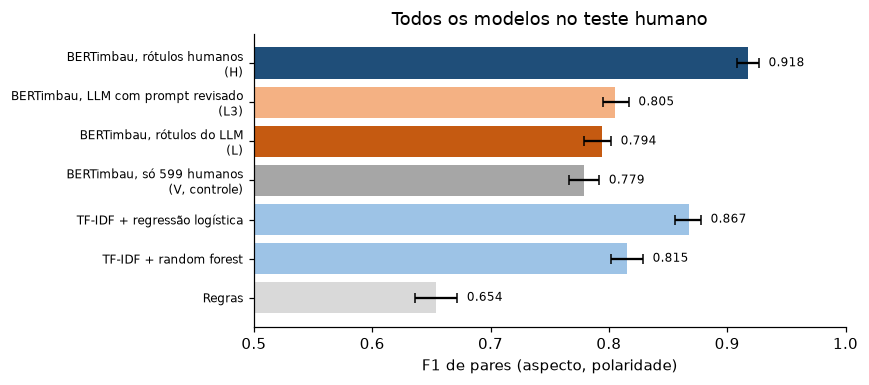

In [8]:
ordem = ["Regras", "TF-IDF + random forest", "TF-IDF + regressão logística", "BERTimbau, só 599 humanos (V, controle)",
         "BERTimbau, rótulos do LLM (L)", "BERTimbau, LLM com prompt revisado (L3)", "BERTimbau, rótulos humanos (H)"]
cores = ["#d9d9d9", COR["tfidf"], COR["tfidf"], COR["controle"], COR["llm"], COR["llm3"], COR["humano"]]
r = resultados.loc[ordem]
lo_hi = np.array([[float(x) for x in s.split("–")] for s in r["IC 95%"]])
y = r["F1 de pares"].astype(float).to_numpy()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(range(len(r)), y, color=cores, xerr=[y - lo_hi[:, 0], lo_hi[:, 1] - y], capsize=3)
ax.set_yticks(range(len(r)), [s.replace(" (", "\n(") for s in r.index], fontsize=8)
for i, v in enumerate(y): ax.text(lo_hi[i, 1] + 0.008, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(0.5, 1.0); ax.set_xlabel("F1 de pares (aspecto, polaridade)"); ax.set_title("Todos os modelos no teste humano")
plt.tight_layout(); plt.show()

In [9]:
display(Markdown("**Comparações pareadas** (bootstrap bilateral, 10.000 reamostras, semente 42) com correção de Holm"))
h42 = ler(RES / "encoders/pred_teste_bertimbau_H_s42.csv")
comp = {"H − TF-IDF": paired_bootstrap(teste, h42, pred["TF-IDF + regressão logística"]),
        "H − V": paired_bootstrap(teste, h42, ler(RES / "encoders/pred_teste_bertimbau_V_s42.csv")),
        "H − L": paired_bootstrap(teste, h42, ler(RES / "h2/pred_teste_bertimbau_L_s42.csv"))}
aj = holm({k: v["p_valor"] for k, v in comp.items()})
display(pd.DataFrame({k: {"diferença": v["diferenca"], "IC 95%": f"{v['ic95'][0]:+.3f} a {v['ic95'][1]:+.3f}", "p (Holm)": aj[k]}
                      for k, v in comp.items()}).T)
display(Markdown("**H1 confirmada:** o BERTimbau supera a melhor linha de base em +0,048 de F1 de pares, com significância estatística."))

**Comparações pareadas** (bootstrap bilateral, 10.000 reamostras, semente 42) com correção de Holm

,diferença,IC 95%,p (Holm)
H − TF-IDF,0.048,+0.038 a +0.059,0.0
H − V,0.136,+0.123 a +0.149,0.0
H − L,0.109,+0.097 a +0.121,0.0


**H1 confirmada:** o BERTimbau supera a melhor linha de base em +0,048 de F1 de pares, com significância estatística.

**Por aspecto (F1 de pares)** — o BERTimbau ganha em todos, mais em recebimento e anúncio

aspecto,produto,entrega,recebimento,anuncio,outros
BERTimbau,0.942,0.955,0.890,0.866,0.836
TF-IDF,0.913,0.918,0.785,0.762,0.774


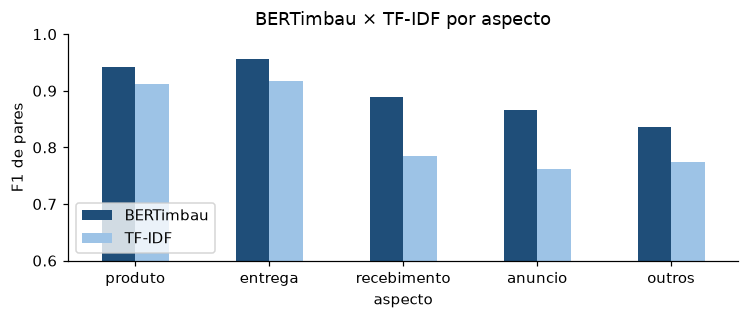

In [10]:
rep_h = sum(per_aspect_report(teste, p).set_index("aspecto") for p in bert["BERTimbau, rótulos humanos (H)"]) / 3
rep_t = per_aspect_report(teste, pred["TF-IDF + regressão logística"]).set_index("aspecto")
por_asp = pd.DataFrame({"BERTimbau": rep_h.f1_pares, "TF-IDF": rep_t.f1_pares}).drop("MÉDIA")
display(Markdown("**Por aspecto (F1 de pares)** — o BERTimbau ganha em todos, mais em recebimento e anúncio"))
display(por_asp.T)
ax = por_asp.plot.bar(figsize=(7, 3), color=[COR["humano"], COR["tfidf"]], rot=0)
ax.set_ylim(0.6, 1); ax.set_ylabel("F1 de pares"); ax.set_title("BERTimbau × TF-IDF por aspecto"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

## 5. H2 — rótulos de um LLM substituem rótulos humanos?

Anotar à mão é caro. A pergunta: se um LLM rotular **os mesmos textos** do treino, o BERTimbau treinado com esses rótulos chega perto do treinado com rótulos humanos?

- **LLM:** Qwen2.5-7B-Instruct, modelo aberto, em 4 bits na GPU gratuita do Colab (custo zero). Seis exemplos fixos no prompt, resposta em JSON. ~1,4 s por texto, ~2 h para os 5.589 textos.
- **Prompt v2** (o original) e **prompt v3** (com regras de desempate escritas depois de olhar os erros do v2).
- Mesma arquitetura, mesmos hiperparâmetros, mesmo teste humano: só muda a origem dos rótulos.

In [11]:
def rotulos_llm(arq, ref):
    q = pd.read_csv(arq).set_index("review_id").loc[ref.review_id].reset_index()
    q.loc[~q.valido.astype(bool), LABEL_COLUMNS] = "ausente"
    return q[LABEL_COLUMNS].fillna("ausente")

q2 = rotulos_llm(RES / "h2/repro_valdev_qwen7b.csv", val_dev)
q3 = rotulos_llm(RES / "h2_v3/repro_valdev_qwen7b_v3.csv", val_dev)
conc = {}
for nome, q in [("Qwen, prompt v2", q2), ("Qwen, prompt v3", q3)]:
    f, lo, hi = bootstrap_ci(val_dev, q)
    conc[nome] = {"F1 de pares vs humano": f, "IC 95%": f"{lo:.3f}–{hi:.3f}", "aspectos por avaliação": (q != "ausente").sum(axis=1).mean()}
conc["Humanos"] = {"F1 de pares vs humano": 1.0, "IC 95%": "", "aspectos por avaliação": (val_dev[LABEL_COLUMNS] != "ausente").sum(axis=1).mean()}
display(Markdown("**Qualidade dos rótulos do LLM** na validação (599 avaliações). O v3 foi ajustado olhando esses erros, então a concordância dele aqui é otimista."))
display(pd.DataFrame(conc).T)

**Qualidade dos rótulos do LLM** na validação (599 avaliações). O v3 foi ajustado olhando esses erros, então a concordância dele aqui é otimista.

,F1 de pares vs humano,IC 95%,aspectos por avaliação
"Qwen, prompt v2",0.772,0.753–0.791,1.962
"Qwen, prompt v3",0.78,0.760–0.800,1.861
Humanos,1.0,,1.544


**Onde o LLM erra:** marca aspectos demais — sobretudo "anúncio" e "outros" — e de menos em "recebimento"

,produto,entrega,recebimento,anuncio,outros
humanos,451,193,102,44,135
Qwen v2,499,207,65,123,281
Qwen v3,514,191,56,87,267


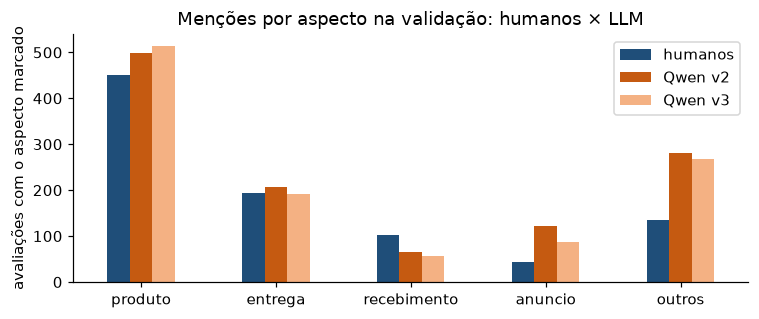

In [12]:
H = val_dev[LABEL_COLUMNS] != "ausente"
mencoes = pd.DataFrame({"humanos": H.sum(), "Qwen v2": (q2 != "ausente").sum(), "Qwen v3": (q3 != "ausente").sum()})
mencoes.index = ASPECTS
display(Markdown("**Onde o LLM erra:** marca aspectos demais — sobretudo \"anúncio\" e \"outros\" — e de menos em \"recebimento\""))
display(mencoes.T)
ax = mencoes.plot.bar(figsize=(7, 3), color=[COR["humano"], COR["llm"], COR["llm3"]], rot=0)
ax.set_ylabel("avaliações com o aspecto marcado"); ax.set_title("Menções por aspecto na validação: humanos × LLM")
plt.tight_layout(); plt.show()

In [13]:
display(Markdown("**Exemplos de divergência** (validação)"))
def marcados(df, i):
    return ", ".join(f"{a}{'+' if df.iloc[i][c] == 'positivo' else '−' if df.iloc[i][c] == 'negativo' else '='}"
                     for a, c in zip(ASPECTS, LABEL_COLUMNS) if df.iloc[i][c] != "ausente")
frases = ["Cor errada", "incompleto. Não indico", "Recomendo. Produto de boa", "Não recebi meu produto! Comprei"]
idx = [val_dev.index[val_dev.texto_modelo.str.startswith(f)][0] for f in frases]
display(pd.DataFrame({"comentário": [val_dev.texto_modelo[i][:110] for i in idx], "humano": [marcados(val_dev, i) for i in idx],
                      "Qwen v2": [marcados(q2, i) for i in idx], "Qwen v3": [marcados(q3, i) for i in idx]}))

**Exemplos de divergência** (validação)

,comentário,humano,Qwen v2,Qwen v3
0,Cor errada. Comprei um iphone 8 dourado e recebi o rosa. Realmente não gostei. Foi a primeira vez que recebi,recebimento−,"produto−, recebimento−, anuncio−","produto−, recebimento−, anuncio−"
1,"incompleto. Não indico, pq falta piso do carrinho, para idade de 1 ano são ainda pequenos e ficam com os pés s","produto−, recebimento−","produto−, anuncio−","produto−, anuncio−"
2,Recomendo. Produto de boa qualidade. e atende bem o que promete.,produto+,"produto+, outros+","produto+, outros+"
3,Não recebi meu produto! Comprei há mais de um mês e não recebi até hoje. Entrega atrasadissima!!,entrega−,"entrega−, outros−","entrega−, outros−"


**Recuperação da distância** entre o controle V (0.779) e o modelo humano H (0.918): L = **11%**, L3 = **18%**

L3 − L (semente 42): -0.004 (IC95% -0.012 a +0.004), p = 0.37 → não significativa


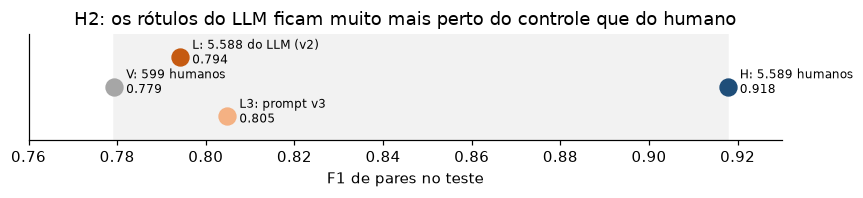

**H2 não confirmada:** 5.588 rótulos do Qwen valem pouco mais que 599 rótulos humanos, e corrigir o prompt não muda isso.

In [14]:
m = resultados["F1 de pares"].astype(float)
H_, V_ = m["BERTimbau, rótulos humanos (H)"], m["BERTimbau, só 599 humanos (V, controle)"]
rec = {k: (m[k] - V_) / (H_ - V_) for k in ["BERTimbau, rótulos do LLM (L)", "BERTimbau, LLM com prompt revisado (L3)"]}
display(Markdown(f"**Recuperação da distância** entre o controle V ({V_:.3f}) e o modelo humano H ({H_:.3f}): "
                 f"L = **{rec['BERTimbau, rótulos do LLM (L)']:.0%}**, L3 = **{rec['BERTimbau, LLM com prompt revisado (L3)']:.0%}**"))
l3_l = paired_bootstrap(teste, ler(RES / "h2_v3/pred_teste_bertimbau_L3_s42.csv"), ler(RES / "h2/pred_teste_bertimbau_L_s42.csv"))
print(f"L3 − L (semente 42): {l3_l['diferenca']:+.3f} (IC95% {l3_l['ic95'][0]:+.3f} a {l3_l['ic95'][1]:+.3f}), p = {l3_l['p_valor']:.2f} → não significativa")

fig, ax = plt.subplots(figsize=(8, 1.9))
ax.axvspan(V_, H_, color="#f2f2f2"); ax.set_xlim(0.76, 0.93); ax.set_ylim(0, 1); ax.set_yticks([])
for nome, cor, txt, yy in [("BERTimbau, só 599 humanos (V, controle)", COR["controle"], "V: 599 humanos", 0.5),
                           ("BERTimbau, rótulos do LLM (L)", COR["llm"], "L: 5.588 do LLM (v2)", 0.78),
                           ("BERTimbau, LLM com prompt revisado (L3)", COR["llm3"], "L3: prompt v3", 0.22),
                           ("BERTimbau, rótulos humanos (H)", COR["humano"], "H: 5.589 humanos", 0.5)]:
    ax.plot(m[nome], yy, "o", color=cor, ms=11); ax.annotate(f"{txt}\n{m[nome]:.3f}", (m[nome], yy), xytext=(8, -4), textcoords="offset points", fontsize=8)
ax.set_xlabel("F1 de pares no teste"); ax.set_title("H2: os rótulos do LLM ficam muito mais perto do controle que do humano")
plt.tight_layout(); plt.show()
display(Markdown("**H2 não confirmada:** 5.588 rótulos do Qwen valem pouco mais que 599 rótulos humanos, e corrigir o prompt não muda isso."))

## 6. H3 — "entrega negativa" acompanha o atraso real?

Os modelos treinados **só no RePro** foram aplicados à metade "relato" da Olist (pedidos entregues, separados por *hash* do pedido e não usados em nenhuma decisão de modelagem). A pergunta é se a probabilidade prevista de **entrega negativa** distingue os pedidos que de fato atrasaram.

Como a nota já se correlaciona com o atraso, a evidência relevante é: (i) o ganho **sobre a nota**; (ii) a AUC **dentro de cada nota**; (iii) um **placebo** (produto negativo), que não deveria acompanhar o atraso.

*AUC: 0,5 = acaso; 1,0 = separa perfeitamente atrasados de não atrasados.*

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

rel = pd.read_csv(RES / "encoders/olist_relato_probs_bertimbau_H_s42.csv")
y = rel.atrasado.to_numpy()
txt = olist.set_index("review_id").loc[rel.review_id, "texto_modelo"].map(clean_classic)
p_tfidf = tfidf.predict_proba(txt)[:, ASPECTS.index("entrega"), POLARITIES.index("negativo")]
rng = np.random.default_rng(SEED)
def auc_ic(s, n=500):
    v = [roc_auc_score(y[i], s[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return f"{roc_auc_score(y, s):.3f} ({np.quantile(v, .025):.3f}–{np.quantile(v, .975):.3f})"
X_nota = pd.get_dummies(rel.nota.astype(str)).to_numpy(float)
cv = lambda X: roc_auc_score(y, cross_val_predict(LogisticRegression(max_iter=1000), X, y, cv=5, method="predict_proba")[:, 1])
print(f"n = {len(rel):,} pedidos entregues, {y.sum():,} atrasados")
display(pd.DataFrame({
    "AUC (IC 95%)": {"só a nota": auc_ic(-rel.nota.to_numpy()), "BERTimbau P(entrega neg)": auc_ic(rel.p_entrega_negativo.to_numpy()),
                     "TF-IDF P(entrega neg)": auc_ic(p_tfidf), "placebo: BERTimbau P(produto neg)": auc_ic(rel.p_produto_negativo.to_numpy())},
    "regressão com a nota (CV 5x)": {"só a nota": f"{cv(X_nota):.3f}", "BERTimbau P(entrega neg)": f"{cv(np.column_stack([X_nota, rel.p_entrega_negativo])):.3f}",
                                     "TF-IDF P(entrega neg)": f"{cv(np.column_stack([X_nota, p_tfidf])):.3f}", "placebo: BERTimbau P(produto neg)": ""}}))

n = 19,239 pedidos entregues, 1,876 atrasados


,AUC (IC 95%),regressão com a nota (CV 5x)
só a nota,0.821 (0.812–0.831),0.817
BERTimbau P(entrega neg),0.830 (0.820–0.839),0.859
TF-IDF P(entrega neg),0.843 (0.833–0.852),0.864
placebo: BERTimbau P(produto neg),0.461 (0.448–0.475),


**AUC dentro de cada nota** — o sinal existe mesmo comparando clientes que deram a mesma nota

,1,2,3,4,5
BERTimbau,0.787,0.765,0.697,0.659,0.539
TF-IDF + RL,0.763,0.742,0.708,0.709,0.633


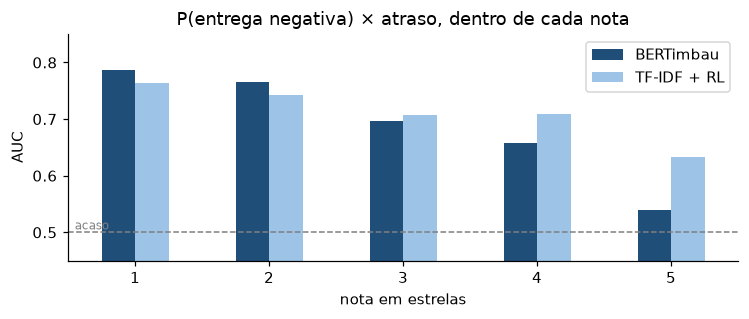

**H3 confirmada:** a entrega negativa prevista acrescenta informação à nota (0,817 → 0,859) e o placebo fica abaixo do acaso. Mas o TF-IDF vai tão bem quanto o BERTimbau aqui: ganho no domínio de treino não garante ganho em outra loja.

In [16]:
por_nota = pd.DataFrame({nome: {n: roc_auc_score(y[rel.nota == n], s[rel.nota == n]) for n in range(1, 6)}
                         for nome, s in [("BERTimbau", rel.p_entrega_negativo.to_numpy()), ("TF-IDF + RL", p_tfidf)]})
display(Markdown("**AUC dentro de cada nota** — o sinal existe mesmo comparando clientes que deram a mesma nota"))
display(por_nota.T)
ax = por_nota.plot.bar(figsize=(7, 3), color=[COR["humano"], COR["tfidf"]], rot=0)
ax.axhline(0.5, ls="--", color="gray", lw=1); ax.text(-0.45, 0.505, "acaso", fontsize=8, color="gray")
ax.set_ylim(0.45, 0.85); ax.set_xlabel("nota em estrelas"); ax.set_ylabel("AUC"); ax.set_title("P(entrega negativa) × atraso, dentro de cada nota")
plt.tight_layout(); plt.show()
display(Markdown("**H3 confirmada:** a entrega negativa prevista acrescenta informação à nota (0,817 → 0,859) e o placebo fica abaixo do acaso. "
                 "Mas o TF-IDF vai tão bem quanto o BERTimbau aqui: ganho no domínio de treino não garante ganho em outra loja."))

## 7. Conclusões

| Hipótese | Resultado | Em uma frase |
|---|---|---|
| **H1** BERTimbau > linhas de base | ✅ 0,918 × 0,867 | Um modelo de linguagem em português entende aspectos melhor que contar palavras. |
| **H2** rótulos de LLM ≈ rótulos humanos | ❌ 0,794 (v2) e 0,805 (v3) × 0,918 | Um LLM aberto de 7B marca aspectos demais; 599 rótulos humanos valem quase o mesmo que 5.588 dele. |
| **H3** entrega negativa acompanha o atraso | ✅ AUC 0,817 → 0,859 | O modelo capta algo real, confirmado por dados da loja, não por anotação. |

**Limitações:** avaliações com polaridade mista (20%) ficam fora do teste, justamente os casos "bom, mas atrasou"; testamos um único LLM; na Olist o modelo clássico foi tão bom quanto o encoder.

**Trabalhos futuros:** LLMs maiores; teste com casos mistos desambiguados à mão; aproveitar as avaliações descartadas no treino; adaptação de domínio para a Olist.

### Onde está cada coisa no repositório
| Pasta / arquivo | O que tem |
|---|---|
| `notebooks/apresentacao.ipynb` | este notebook |
| `notebooks/experimentos.ipynb` | tudo que roda na GPU (BERTimbau, Qwen, aplicação na Olist) |
| `notebooks/h2_prompt_v3.ipynb` | a rodada com o prompt revisado |
| `src/absa/` | o código: dados, métricas, modelos, rotulagem pelo LLM |
| `results/` | predições e resumos salvos de cada experimento |
| `artigo/linguamatica/` | o artigo em LaTeX (modelo Linguamática) |